# Regressão - Previsão da Nota Final de Alunos

## 1. Definição do problema

Identificar cedo os alunos que podem terminar o ano com nota baixa permite que a escola ofereça reforço, acompanhamento ou converse com a família antes que seja tarde. Para isso, é útil saber se dá para estimar a nota final a partir de informações que a escola já tem, como as notas dos bimestres anteriores, faltas e dados sobre a vida do aluno.

**Pergunta principal:** É possível prever a nota final de um aluno de matemática a partir das notas anteriores e de informações sobre sua rotina e família?

**Tipo de problema:** Regressão, pois a variável alvo é um número (nota de 0 a 20).

## 2. Apresentação da base de dados

- **Nome:** Student Performance (arquivo `student-mat.csv`, disciplina de matemática)
- **Origem:** dados coletados em duas escolas públicas de Portugal (2005-2006) por questionários e registros escolares, publicados no UCI Machine Learning Repository: https://archive.ics.uci.edu/dataset/320/student+performance
- **Registros:** 395 alunos
- **Colunas:** 33 (32 variáveis de entrada e 1 variável alvo)

Principais colunas:

| Coluna | Significado |
|---|---|
| school | escola (GP ou MS) |
| sex, age | sexo e idade do aluno |
| Medu, Fedu | escolaridade da mãe e do pai (0 = nenhuma até 4 = ensino superior) |
| studytime | tempo de estudo semanal (1 = menos de 2h até 4 = mais de 10h) |
| failures | número de reprovações anteriores |
| schoolsup, famsup | se recebe apoio extra da escola / da família |
| higher | se quer fazer ensino superior |
| internet | se tem internet em casa |
| goout | quanto sai com os amigos (1 = muito pouco até 5 = muito) |
| Dalc, Walc | consumo de álcool durante a semana / no fim de semana (1 a 5) |
| absences | número de faltas |
| G1, G2 | notas do 1º e do 2º período (0 a 20) |
| G3 | **variável alvo**: nota final (0 a 20) |

As outras colunas trazem informações sobre família, tempo livre, saúde e atividades extracurriculares.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# carregando os dados (o arquivo usa ; como separador)
df = pd.read_csv('../dados/student-mat.csv', sep=';')

print('Linhas:', df.shape[0])
print('Colunas:', df.shape[1])

Linhas: 395
Colunas: 33


## 3. Análise exploratória dos dados

In [3]:
# primeiras linhas
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [4]:
# tipos de dados
df.dtypes

school          str
sex             str
age           int64
address         str
famsize         str
Pstatus         str
Medu          int64
Fedu          int64
Mjob            str
Fjob            str
reason          str
guardian        str
traveltime    int64
studytime     int64
failures      int64
schoolsup       str
famsup          str
paid            str
activities      str
nursery         str
higher          str
internet        str
romantic        str
famrel        int64
freetime      int64
goout         int64
Dalc          int64
Walc          int64
health        int64
absences      int64
G1            int64
G2            int64
G3            int64
dtype: object

In [5]:
# valores ausentes
print('Total de valores ausentes:', df.isnull().sum().sum())

Total de valores ausentes: 0


In [6]:
# registros duplicados
print('Duplicados:', df.duplicated().sum())

Duplicados: 0


In [7]:
# estatisticas basicas
df.describe().round(2)

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00,395.00
mean,16.70,2.75,2.52,1.45,2.04,0.33,3.94,3.24,3.11,1.48,2.29,3.55,5.71,10.91,10.71,10.42
std,1.28,1.09,1.09,0.70,0.84,0.74,0.90,1.00,1.11,0.89,1.29,1.39,8.00,3.32,3.76,4.58
min,15.00,0.00,0.00,1.00,1.00,0.00,1.00,1.00,1.00,1.00,1.00,1.00,0.00,3.00,0.00,0.00
25%,16.00,2.00,2.00,1.00,1.00,0.00,4.00,3.00,2.00,1.00,1.00,3.00,0.00,8.00,9.00,8.00
50%,17.00,3.00,2.00,1.00,2.00,0.00,4.00,3.00,3.00,1.00,2.00,4.00,4.00,11.00,11.00,11.00
75%,18.00,4.00,3.00,2.00,2.00,0.00,5.00,4.00,4.00,2.00,3.00,5.00,8.00,13.00,13.00,14.00
max,22.00,4.00,4.00,4.00,4.00,3.00,5.00,5.00,5.00,5.00,5.00,5.00,75.00,19.00,19.00,20.00


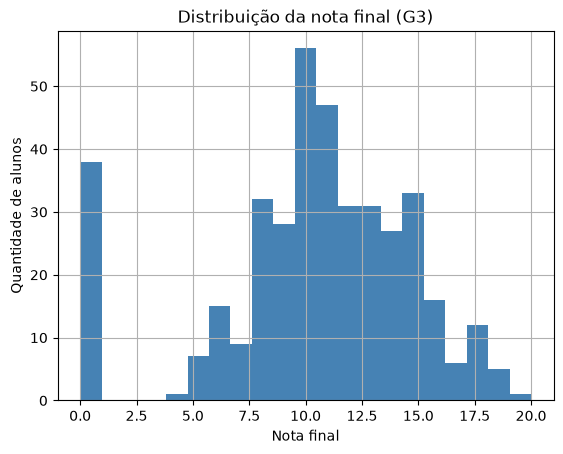

In [8]:
# distribuicao da nota final
df['G3'].hist(bins=21, color='steelblue')
plt.title('Distribuição da nota final (G3)')
plt.xlabel('Nota final')
plt.ylabel('Quantidade de alunos')
plt.show()

In [9]:
# alunos com nota final zero
zerados = df[df['G3'] == 0]
print('Alunos com nota final 0:', len(zerados))
print()
print(zerados[['G1', 'G2', 'G3', 'absences']].describe().round(1))

Alunos com nota final 0: 38

         G1    G2    G3  absences
count  38.0  38.0  38.0      38.0
mean    7.5   4.7   0.0       0.0
std     1.8   3.7   0.0       0.0
min     4.0   0.0   0.0       0.0
25%     6.0   0.0   0.0       0.0
50%     7.0   5.0   0.0       0.0
75%     9.0   8.0   0.0       0.0
max    12.0  10.0   0.0       0.0


O histograma mostra um grupo de alunos com nota final 0, separado do resto. Esses 38 alunos tiveram notas no 1º período (entre 4 e 12) e têm **zero faltas**, o que indica que eles provavelmente abandonaram a disciplina ou não fizeram a prova final, e não que tiraram zero de verdade.

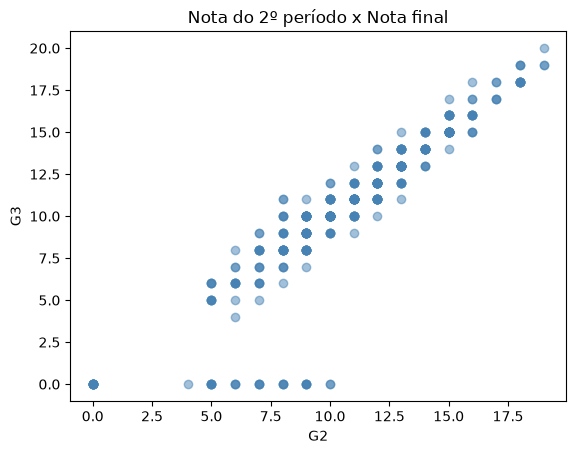

In [10]:
# relacao entre a nota do 2o periodo e a nota final
plt.scatter(df['G2'], df['G3'], alpha=0.5, color='steelblue')
plt.title('Nota do 2º período x Nota final')
plt.xlabel('G2')
plt.ylabel('G3')
plt.show()

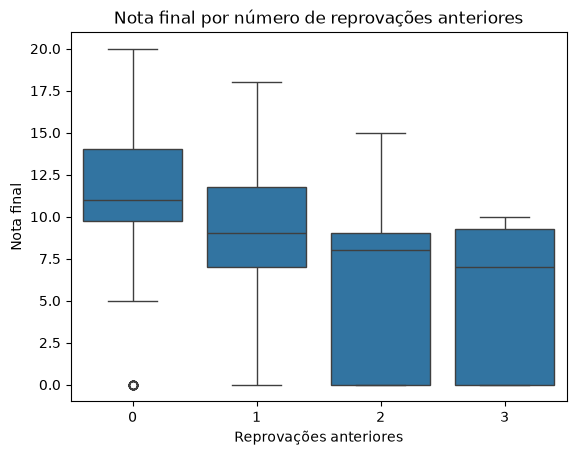

In [11]:
# nota final por numero de reprovacoes
sns.boxplot(data=df, x='failures', y='G3')
plt.title('Nota final por número de reprovações anteriores')
plt.xlabel('Reprovações anteriores')
plt.ylabel('Nota final')
plt.show()

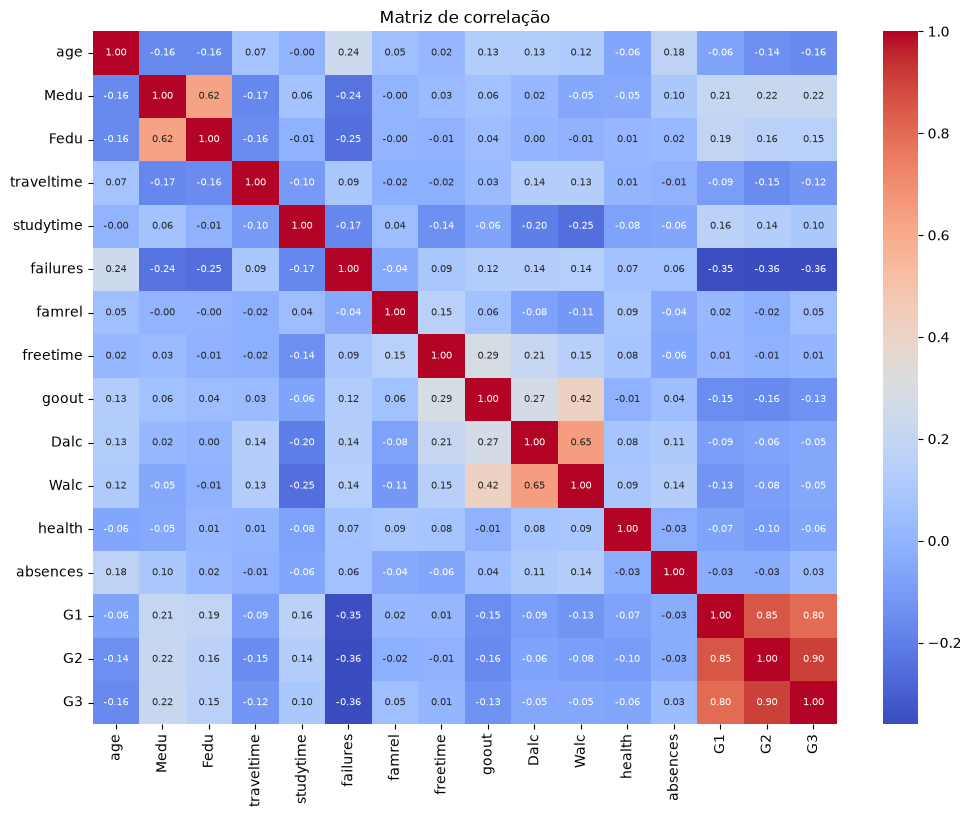

In [12]:
# matriz de correlacao das colunas numericas
plt.figure(figsize=(12, 9))
sns.heatmap(df.select_dtypes('number').corr(), annot=True, fmt='.2f', cmap='coolwarm', annot_kws={'size': 7})
plt.title('Matriz de correlação')
plt.show()

**O que a análise mostrou:**

- A base tem 395 alunos, 33 colunas (16 numéricas e 17 de texto), sem valores ausentes e sem duplicados.
- A nota final média é 10,4 (de 0 a 20). Existem 38 alunos com nota final 0 que provavelmente não fizeram a prova final, e isso será tratado na preparação.
- As notas dos períodos anteriores têm relação muito forte com a nota final: correlação de 0,90 para G2 e 0,80 para G1. O gráfico de dispersão mostra os pontos quase em linha reta.
- O **número de reprovações anteriores** é a variável com a correlação negativa mais forte (-0,36): a nota média cai de 11,3 para quem nunca reprovou para 5,7 para quem reprovou 3 vezes.
- A escolaridade da mãe (0,22) e do pai (0,15) têm uma relação positiva fraca com a nota. Sair muito com os amigos (-0,13) e a idade (-0,16) têm relação negativa fraca.

## 4. Preparação dos dados

Decisões tomadas:

1. **Duplicados e ausentes:** a base não tem registros duplicados nem valores ausentes.
2. **Remoção dos alunos com nota final 0:** os 38 alunos com G3 = 0 foram removidos. Como explicado na análise, eles provavelmente desistiram ou não fizeram a prova, então não representam uma nota real. Mantê-los faria o modelo tentar prever "desistência", que é outro problema.
3. **Notas G1 e G2 mantidas:** elas são as variáveis mais importantes. Em uma situação real, a escola já tem essas notas antes do fim do ano, então faz sentido usá-las para prever a nota final.
4. **Variáveis categóricas:** as 17 colunas de texto (escola, sexo, profissão dos pais, colunas yes/no etc.) foram transformadas com **one-hot encoding**. Foi usado `drop_first=True`, que remove uma das colunas criadas de cada variável porque ela é redundante (por exemplo, se `sex_M` é 0, já se sabe que o aluno é do sexo feminino).
5. **Treino e teste:** 80% treino e 20% teste.
6. **Padronização:** `StandardScaler`, importante principalmente para o KNN e a Ridge, que são sensíveis à escala.

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# removendo os alunos com nota final 0
df = df[df['G3'] > 0]
print('Alunos depois da remoção:', len(df))

# one-hot encoding das colunas de texto
df = pd.get_dummies(df, drop_first=True, dtype=int)
print('Colunas depois do one-hot:', df.shape[1])

Alunos depois da remoção: 357
Colunas depois do one-hot: 42


In [14]:
# separando entradas (X) e alvo (y)
X = df.drop(columns='G3')
y = df['G3']

# dividindo em treino e teste
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# padronizando
scaler = StandardScaler()
X_treino_pad = scaler.fit_transform(X_treino)
X_teste_pad = scaler.transform(X_teste)

print('Treino:', X_treino_pad.shape)
print('Teste:', X_teste_pad.shape)

Treino: (285, 41)
Teste: (72, 41)


## 5. Escolha dos modelos

Foram escolhidos 5 modelos de regressão:

- **Regressão Linear:** encontra a reta (ou plano) que melhor relaciona as variáveis com a nota. É o modelo mais simples e serve como base de comparação. Faz sentido aqui porque a relação entre G2 e G3 é quase uma reta.
- **Ridge:** é uma regressão linear com uma penalização que evita coeficientes muito grandes. Ajuda quando há muitas colunas e poucos registros, como nesta base (mais de 40 colunas e menos de 300 alunos no treino).
- **Árvore de Decisão Regressora:** divide os alunos em grupos por regras (por exemplo "G2 > 12") e prevê a média do grupo. Limitada a profundidade 5.
- **Random Forest Regressor:** média de várias árvores, mais estável que uma árvore sozinha.
- **KNN Regressor:** prevê a nota como a média das notas dos 5 alunos mais parecidos.

## 6. Treinamento dos modelos

- **Dados de treino:** 285 alunos (80%)
- **Dados de teste:** 72 alunos (20%)

Cada modelo aprende com os dados de treino (`fit`) e depois prevê a nota final dos alunos de teste (`predict`).

In [15]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor

modelos = {
    'Regressão Linear': LinearRegression(),
    'Ridge': Ridge(alpha=1.0),
    'Árvore de Decisão': DecisionTreeRegressor(max_depth=5, random_state=42),
    'Random Forest': RandomForestRegressor(random_state=42),
    'KNN': KNeighborsRegressor(n_neighbors=5)
}

# treinando cada modelo e guardando as previsoes no teste
previsoes = {}
for nome, modelo in modelos.items():
    modelo.fit(X_treino_pad, y_treino)
    previsoes[nome] = modelo.predict(X_teste_pad)
    print(nome, '- treinado')

Regressão Linear - treinado
Ridge - treinado
Árvore de Decisão - treinado


Random Forest - treinado


KNN - treinado


## 7. Avaliação dos modelos

Métricas utilizadas:

- **MAE (erro absoluto médio):** em média, quantos pontos a previsão erra para mais ou para menos.
- **MSE (erro quadrático médio):** média dos erros ao quadrado. Pune mais os erros grandes.
- **RMSE (raiz do MSE):** volta o MSE para a mesma unidade da nota, fica mais fácil de interpretar.
- **R² (coeficiente de determinação):** quanto da variação das notas o modelo consegue explicar. Vai até 1, e quanto mais perto de 1, melhor.

In [16]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

resultados = []
for nome, y_prev in previsoes.items():
    mse = mean_squared_error(y_teste, y_prev)
    resultados.append({
        'Modelo': nome,
        'MAE': mean_absolute_error(y_teste, y_prev),
        'MSE': mse,
        'RMSE': np.sqrt(mse),
        'R²': r2_score(y_teste, y_prev)
    })

tabela = pd.DataFrame(resultados).sort_values('R²', ascending=False)
tabela.round(3)

,Modelo,MAE,MSE,RMSE,R²
3,Random Forest,0.599,0.674,0.821,0.930
0,Regressão Linear,0.675,0.809,0.900,0.916
1,Ridge,0.675,0.810,0.900,0.916
2,Árvore de Decisão,0.698,0.878,0.937,0.909
4,KNN,1.608,3.987,1.997,0.586


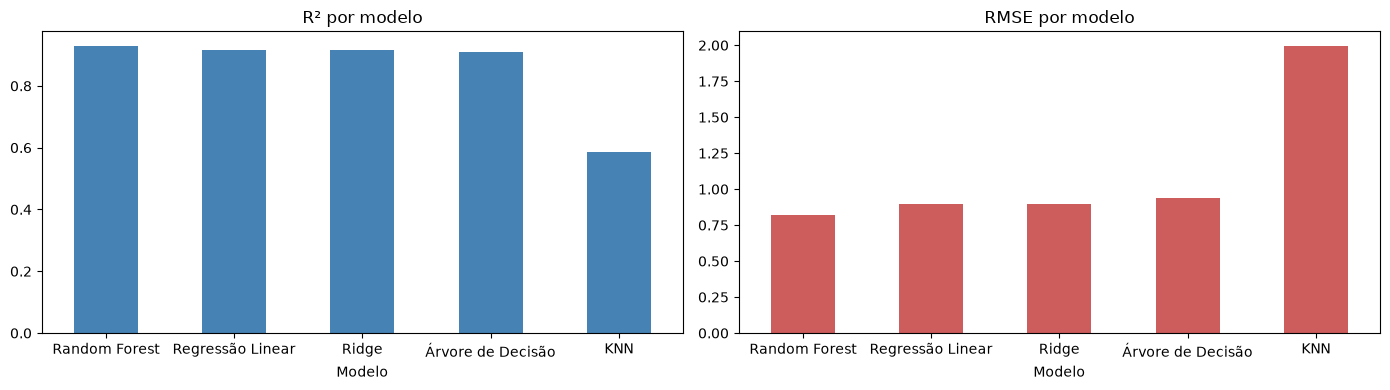

In [17]:
# comparando o R2 e o RMSE dos modelos
fig, eixos = plt.subplots(1, 2, figsize=(14, 4))
tabela.plot(x='Modelo', y='R²', kind='bar', ax=eixos[0], legend=False, color='steelblue')
eixos[0].set_title('R² por modelo')
eixos[0].tick_params(axis='x', rotation=0)
tabela.plot(x='Modelo', y='RMSE', kind='bar', ax=eixos[1], legend=False, color='indianred')
eixos[1].set_title('RMSE por modelo')
eixos[1].tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

Melhor modelo pelo R²: Random Forest


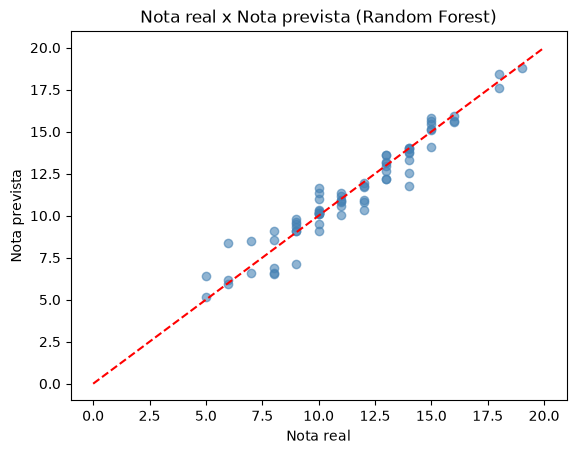

In [18]:
# valores reais x previstos do melhor modelo
melhor_nome = tabela.iloc[0]['Modelo']
print('Melhor modelo pelo R²:', melhor_nome)

plt.scatter(y_teste, previsoes[melhor_nome], alpha=0.6, color='steelblue')
plt.plot([0, 20], [0, 20], color='red', linestyle='--')
plt.title('Nota real x Nota prevista (' + melhor_nome + ')')
plt.xlabel('Nota real')
plt.ylabel('Nota prevista')
plt.show()

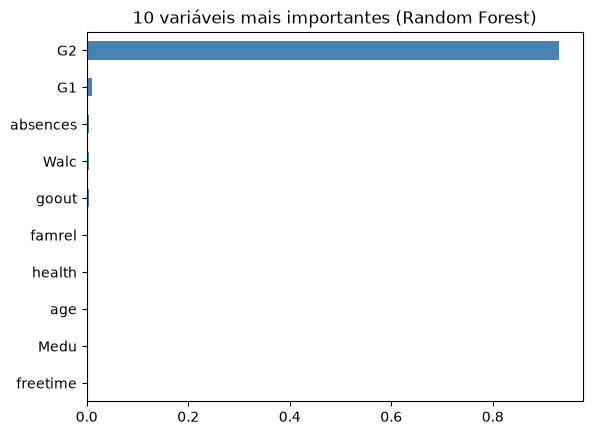

In [19]:
# variaveis com mais peso no random forest
importancia = pd.Series(modelos['Random Forest'].feature_importances_, index=X.columns)
importancia.sort_values().tail(10).plot(kind='barh', color='steelblue')
plt.title('10 variáveis mais importantes (Random Forest)')
plt.show()

Como a nota G2 domina o modelo, foi feito um teste extra: treinar os mesmos modelos **sem as notas G1 e G2**, para ver se dá para prever a nota final só com as informações sobre o aluno e sua família.

In [20]:
# testando os modelos sem as notas G1 e G2
X_treino_sem = X_treino.drop(columns=['G1', 'G2'])
X_teste_sem = X_teste.drop(columns=['G1', 'G2'])

scaler_sem = StandardScaler()
X_treino_sem_pad = scaler_sem.fit_transform(X_treino_sem)
X_teste_sem_pad = scaler_sem.transform(X_teste_sem)

modelos_sem = {
    'Regressão Linear': LinearRegression(),
    'Ridge': Ridge(alpha=1.0),
    'Árvore de Decisão': DecisionTreeRegressor(max_depth=5, random_state=42),
    'Random Forest': RandomForestRegressor(random_state=42),
    'KNN': KNeighborsRegressor(n_neighbors=5)
}

resultados_sem = []
for nome, modelo_sem in modelos_sem.items():
    modelo_sem.fit(X_treino_sem_pad, y_treino)
    y_prev = modelo_sem.predict(X_teste_sem_pad)
    resultados_sem.append({
        'Modelo': nome,
        'MAE': mean_absolute_error(y_teste, y_prev),
        'RMSE': np.sqrt(mean_squared_error(y_teste, y_prev)),
        'R²': r2_score(y_teste, y_prev)
    })

pd.DataFrame(resultados_sem).sort_values('R²', ascending=False).round(3)

,Modelo,MAE,RMSE,R²
3,Random Forest,2.247,2.756,0.211
1,Ridge,2.318,2.768,0.205
0,Regressão Linear,2.323,2.773,0.202
4,KNN,2.533,3.188,-0.055
2,Árvore de Decisão,2.527,3.210,-0.070


**Interpretação dos resultados:**

- Com as notas G1 e G2, o **Random Forest** foi o melhor modelo: R² de 0,930 e MAE de 0,60, ou seja, ele erra em média 0,6 ponto numa escala de 0 a 20. A Regressão Linear e a Ridge ficaram muito perto (R² de 0,916), o que mostra que a relação entre as notas é quase linear.
- O **KNN** teve o pior resultado (R² de 0,586). Ele dá o mesmo peso para todas as 41 colunas na hora de procurar alunos parecidos, então colunas pouco úteis atrapalham e a G2 perde importância.
- No gráfico de valores reais x previstos, os pontos ficam bem próximos da linha vermelha, o que confirma o bom ajuste.
- Porém o gráfico de importância mostra que o Random Forest usa quase só a **G2** (93% da importância). Na prática, o modelo aprendeu que "a nota final é parecida com a nota do 2º período".
- No teste **sem G1 e G2**, o melhor R² cai para 0,211 e o erro médio sobe para 2,2 pontos. A Árvore de Decisão e o KNN ficaram até com R² negativo, o que significa que foram piores do que simplesmente prever a nota média para todo mundo. Isso mostra que as informações sobre a vida do aluno e da família, sozinhas, explicam pouco da nota final.

## 8. Exemplo de previsão

Usando o melhor modelo para prever a nota final de 6 alunos do conjunto de teste e comparando com a nota real.

In [21]:
melhor_modelo = modelos[melhor_nome]

exemplos = X_teste.head(6)
exemplos_pad = scaler.transform(exemplos)

resultado = exemplos[['G1', 'G2', 'failures', 'absences']].copy()
resultado['nota_prevista'] = melhor_modelo.predict(exemplos_pad).round(1)
resultado['nota_real'] = y_teste.head(6).values
resultado['erro'] = (resultado['nota_prevista'] - resultado['nota_real']).round(1)
resultado

,G1,G2,failures,absences,nota_prevista,nota_real,erro
243,13,12,0,0,11.7,12,-0.3
42,19,18,0,2,18.4,18,0.4
319,11,11,0,2,10.6,11,-0.4
328,10,9,0,7,9.6,9,0.6
56,14,15,0,0,15.6,15,0.6
370,7,7,2,4,7.2,9,-1.8


Nos 6 exemplos, o erro ficou abaixo de 1 ponto em 5 alunos. O maior erro foi no último aluno (1,8 ponto), que tinha 7 nos dois períodos e 2 reprovações, mas conseguiu 9 na nota final.

## 9. Conclusão

**Resumo:** o objetivo foi prever a nota final de alunos de matemática de duas escolas de Portugal usando as notas anteriores e informações sobre a rotina e a família. Foram testados 5 modelos de regressão.

**Principais descobertas:** a nota do 2º período é de longe a melhor forma de prever a nota final. Entre as outras informações, o número de reprovações anteriores é a que mais pesa. Também foi encontrado um grupo de alunos com nota final 0 que pareciam ter desistido, e eles foram removidos.

**Desempenho:** o melhor modelo foi o Random Forest, com R² de 0,93 e erro médio de 0,6 ponto. A resposta para a pergunta é **sim, é possível prever a nota final com boa precisão quando já se conhecem as notas anteriores**. Sem essas notas, o modelo só explica cerca de 21% da variação, então a previsão fica bem fraca.

**Limitações:**
- Base pequena (357 alunos depois da limpeza) e de apenas duas escolas, então o resultado pode não valer para outras escolas.
- O modelo depende quase totalmente da G2, então ele só ajuda perto do fim do ano, quando já existe pouco tempo para agir.
- Os alunos que desistiram foram removidos, mas eles são justamente um grupo que a escola gostaria de identificar.
- Muitas variáveis vêm de questionário (como consumo de álcool e tempo de estudo) e dependem da sinceridade dos alunos.

**Melhorias futuras:**
- Criar um modelo usando só a G1, que é conhecida mais cedo, para dar mais tempo à escola agir.
- Fazer um modelo de classificação separado para prever quais alunos têm risco de desistir (os que tinham nota 0).
- Usar validação cruzada, já que a base é pequena e uma única divisão treino/teste pode variar bastante.
- Juntar a base de português (`student-por.csv`) para ter mais alunos.

**Opinião crítica:** o Machine Learning funciona bem aqui, mas o resultado alto acontece principalmente porque as notas anteriores já dizem quase tudo. O teste sem G1 e G2 mostra que prever o desempenho só pelo perfil do aluno é bem mais difícil. Além disso, usar dados como a escolaridade dos pais ou o consumo de álcool para "rotular" um aluno pode gerar preconceito. O ideal seria usar o modelo apenas como um alerta para oferecer apoio, e nunca para julgar ou excluir alunos.